
# Sesión 02 — Modelos de Clasificación
**Ingeniería del Conocimiento (ISO56B)** · UNCP · 2026-II

**Docente:** Msc. Jaime Antonio Huaytalla Pariona

**Dataset:** Breast Cancer Wisconsin (569 muestras, 30 features, clasificación binaria)

---

## 1. Configuración del entorno

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    precision_score, recall_score, f1_score, roc_curve, auc,
    ConfusionMatrixDisplay, RocCurveDisplay
)

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11
sns.set_style('whitegrid')

print('✓ Librerías cargadas correctamente')

✓ Librerías cargadas correctamente


---
## 2. Carga y exploración del dataset

El dataset **Breast Cancer Wisconsin** contiene 569 muestras de biopsias de mama con 30 features numéricas computadas a partir de imágenes digitalizadas de aspiración con aguja fina (FNA). El target es binario: **maligno (0)** o **benigno (1)**.

In [2]:
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target
df['diagnosis'] = df['target'].map({0: 'maligno', 1: 'benigno'})

print(f'Dataset: {df.shape[0]} muestras, {df.shape[1]-2} features')
print(f'\nDistribución de clases:')
print(df['diagnosis'].value_counts())
print(f'\nProporción: {df["target"].mean():.1%} benigno, {1-df["target"].mean():.1%} maligno')

Dataset: 569 muestras, 30 features

Distribución de clases:
diagnosis
benigno    357
maligno    212
Name: count, dtype: int64

Proporción: 62.7% benigno, 37.3% maligno


In [3]:
df.describe().round(3)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,...,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000
mean,14.127,19.290,91.969,654.889,0.096,0.104,0.089,0.049,0.181,0.063,...,25.677,107.261,880.583,0.132,0.254,0.272,0.115,0.290,0.084,0.627
std,3.524,4.301,24.299,351.914,0.014,0.053,0.080,0.039,0.027,0.007,...,6.146,33.603,569.357,0.023,0.157,0.209,0.066,0.062,0.018,0.484
min,6.981,9.710,43.790,143.500,0.053,0.019,0.000,0.000,0.106,0.050,...,12.020,50.410,185.200,0.071,0.027,0.000,0.000,0.156,0.055,0.000
25%,11.700,16.170,75.170,420.300,0.086,0.065,0.030,0.020,0.162,0.058,...,21.080,84.110,515.300,0.117,0.147,0.114,0.065,0.250,0.071,0.000
50%,13.370,18.840,86.240,551.100,0.096,0.093,0.062,0.034,0.179,0.062,...,25.410,97.660,686.500,0.131,0.212,0.227,0.100,0.282,0.080,1.000
75%,15.780,21.800,104.100,782.700,0.105,0.130,0.131,0.074,0.196,0.066,...,29.720,125.400,1084.000,0.146,0.339,0.383,0.161,0.318,0.092,1.000
max,28.110,39.280,188.500,2501.000,0.163,0.345,0.427,0.201,0.304,0.097,...,49.540,251.200,4254.000,0.223,1.058,1.252,0.291,0.664,0.208,1.000


---
## 3. Análisis exploratorio orientado a clasificación

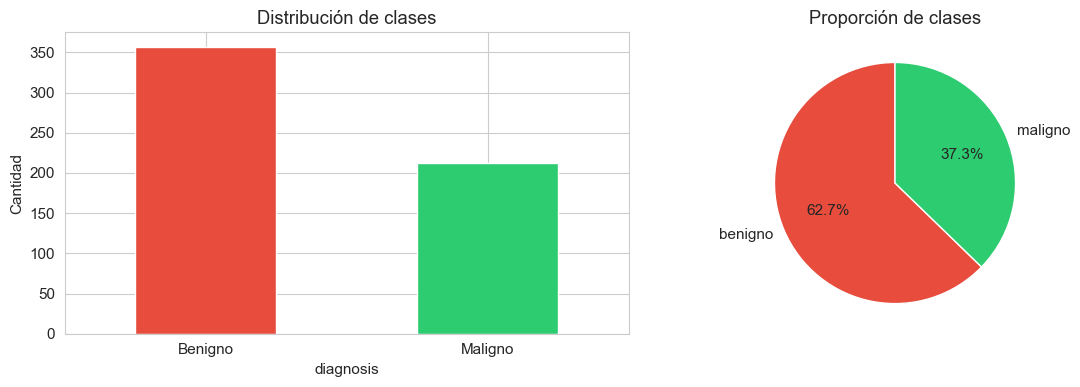

In [4]:
# 3.1  Distribución de clases
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Conteo
colors = ['#e74c3c', '#2ecc71']
df['diagnosis'].value_counts().plot(kind='bar', ax=axes[0], color=colors)
axes[0].set_title('Distribución de clases')
axes[0].set_ylabel('Cantidad')
axes[0].set_xticklabels(['Benigno', 'Maligno'], rotation=0)

# Pie chart
df['diagnosis'].value_counts().plot(kind='pie', ax=axes[1], colors=colors,
    autopct='%1.1f%%', startangle=90)
axes[1].set_ylabel('')
axes[1].set_title('Proporción de clases')

plt.tight_layout()
plt.show()

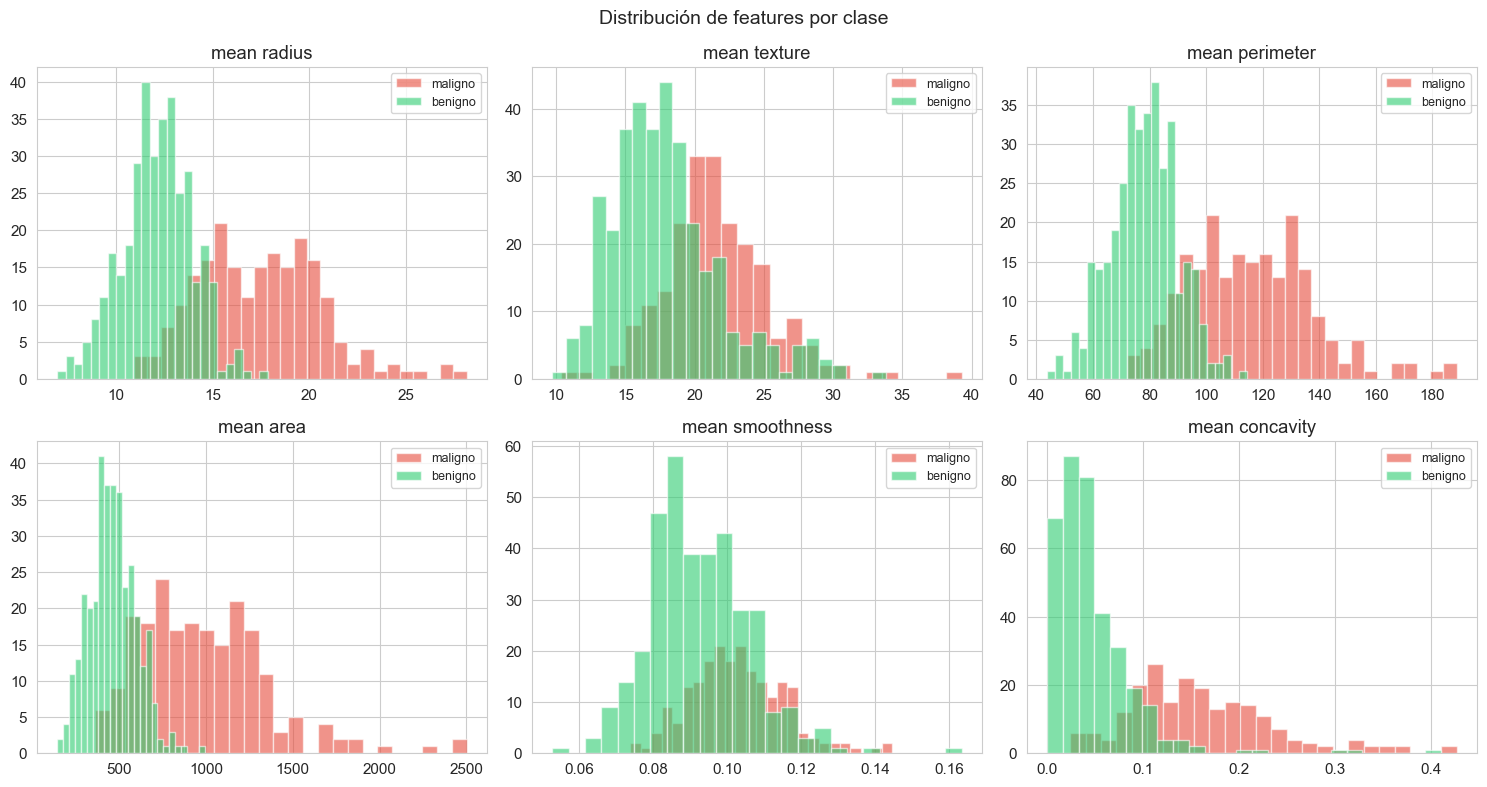

In [5]:
# 3.2  Distribución de features clave por clase
key_features = ['mean radius', 'mean texture', 'mean perimeter',
                'mean area', 'mean smoothness', 'mean concavity']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, feat in enumerate(key_features):
    ax = axes[i//3, i%3]
    for label, color in zip([0, 1], colors):
        subset = df[df['target'] == label][feat]
        ax.hist(subset, bins=25, alpha=0.6, color=color,
                label='maligno' if label == 0 else 'benigno')
    ax.set_title(feat)
    ax.legend(fontsize=9)

plt.suptitle('Distribución de features por clase', fontsize=14)
plt.tight_layout()
plt.show()

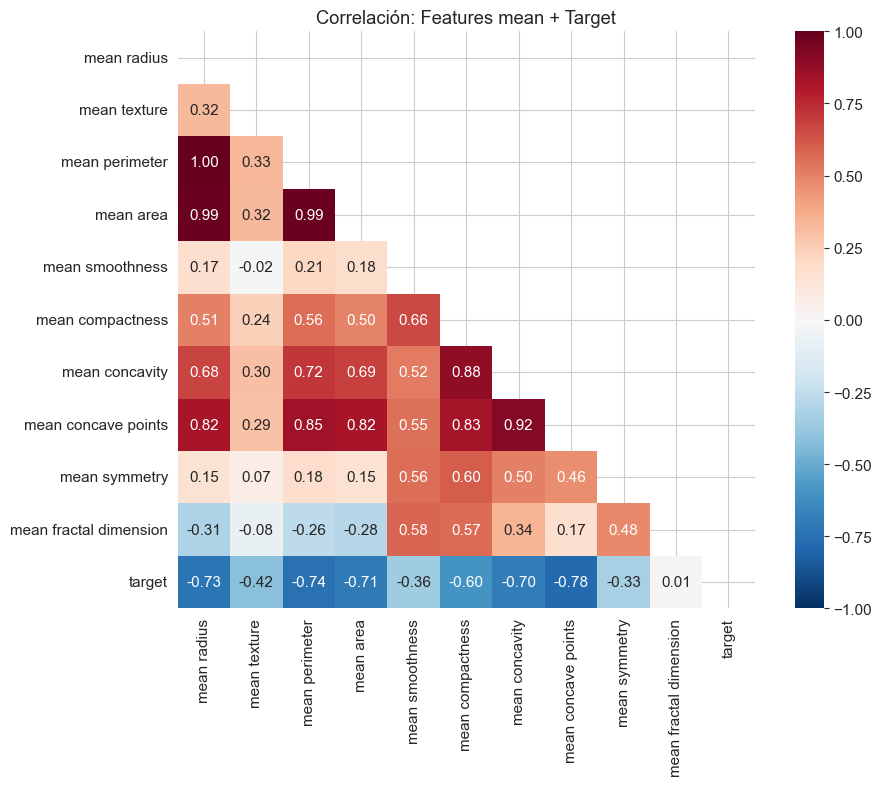

In [6]:
# 3.3  Matriz de correlación (features mean)
mean_features = [c for c in df.columns if 'mean' in c]
plt.figure(figsize=(10, 8))
corr = df[mean_features + ['target']].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, square=True)
plt.title('Correlación: Features mean + Target')
plt.tight_layout()
plt.show()

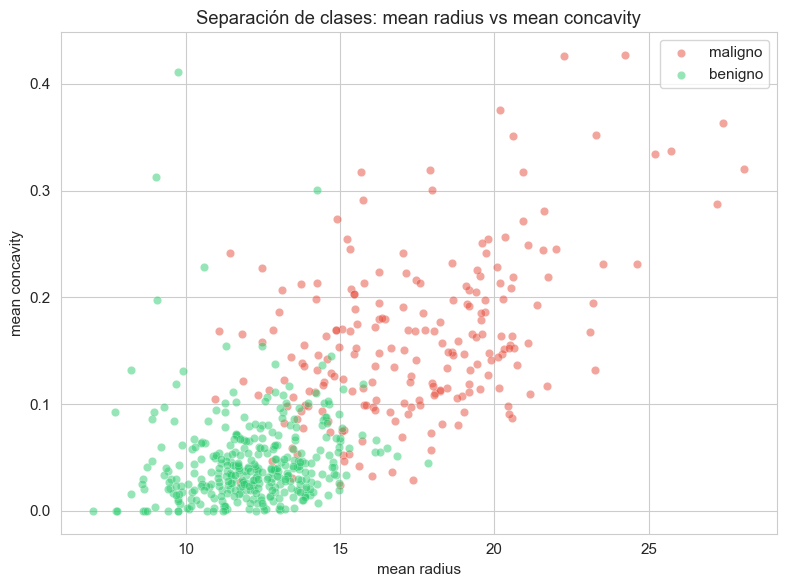

In [7]:
# 3.4  Scatter plot: 2 features más discriminativas
fig, ax = plt.subplots(figsize=(8, 6))
for label, color, name in zip([0, 1], colors, ['maligno', 'benigno']):
    mask = df['target'] == label
    ax.scatter(df.loc[mask, 'mean radius'], df.loc[mask, 'mean concavity'],
              alpha=0.5, c=color, label=name, edgecolors='w', linewidth=0.3)
ax.set_xlabel('mean radius')
ax.set_ylabel('mean concavity')
ax.set_title('Separación de clases: mean radius vs mean concavity')
ax.legend()
plt.tight_layout()
plt.show()

---
## 4. Preparación de datos

In [8]:
X = df[data.feature_names].copy()
y = df['target'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Entrenamiento: {X_train.shape[0]} muestras')
print(f'Test:          {X_test.shape[0]} muestras')
print(f'\nProporción en train: {y_train.mean():.1%} benigno')
print(f'Proporción en test:  {y_test.mean():.1%} benigno')

# Stratified K-Fold para validación cruzada
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Entrenamiento: 455 muestras
Test:          114 muestras

Proporción en train: 62.6% benigno
Proporción en test:  63.2% benigno


### Funciones auxiliares para evaluación de clasificadores

In [9]:
def eval_classifier(model, X_tr, y_tr, X_te, y_te, model_name='Modelo'):
    """Evalúa un clasificador: métricas, matriz de confusión y reporte."""
    y_pred = model.predict(X_te)
    
    metrics = {
        'Accuracy':  accuracy_score(y_te, y_pred),
        'Precision': precision_score(y_te, y_pred, zero_division=0),
        'Recall':    recall_score(y_te, y_pred),
        'F1-Score':  f1_score(y_te, y_pred)
    }
    
    print(f'=== {model_name} ===')
    for k, v in metrics.items():
        print(f'  {k}: {v:.4f}')
    
    # Matriz de confusión
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    cm = confusion_matrix(y_te, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
                xticklabels=['Maligno', 'Benigno'],
                yticklabels=['Maligno', 'Benigno'])
    axes[0].set_title(f'Matriz de Confusión — {model_name}')
    axes[0].set_xlabel('Predicción')
    axes[0].set_ylabel('Real')
    
    # Desglose FP y FN
    tn, fp, fn, tp = cm.ravel()
    labels = ['TN\n(benigno\ncorrecto)', 'FP\n(benigno→\nmaligno)',
              'FN\n(maligno→\nbenigno)', 'TP\n(maligno\ncorrecto)']
    values = [tn, fp, fn, tp]
    bar_colors = ['#2ecc71', '#f39c12', '#e74c3c', '#3498db']
    axes[1].bar(labels, values, color=bar_colors)
    axes[1].set_title(f'Desglose — {model_name}')
    axes[1].set_ylabel('Cantidad')
    
    plt.tight_layout()
    plt.show()
    
    print(f'\n  FN (maligno no detectado): {fn}')
    print(f'  FP (benigno como maligno): {fp}')
    print(f'\nReporte completo:')
    print(classification_report(y_te, y_pred,
          target_names=['maligno', 'benigno']))
    
    return metrics


def plot_roc(model, X_te, y_te, model_name='Modelo', ax=None):
    """Genera la curva ROC de un modelo."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))
    
    if hasattr(model, 'predict_proba'):
        y_score = model.predict_proba(X_te)[:, 1]
    elif hasattr(model, 'decision_function'):
        y_score = model.decision_function(X_te)
    else:
        print(f'{model_name}: no soporta probabilidades')
        return None
    
    fpr, tpr, _ = roc_curve(y_te, y_score)
    roc_auc = auc(fpr, tpr)
    
    ax.plot(fpr, tpr, linewidth=2,
            label=f'{model_name} (AUC = {roc_auc:.4f})')
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.3)
    ax.set_xlabel('Tasa de Falsos Positivos (FPR)')
    ax.set_ylabel('Tasa de Verdaderos Positivos (TPR)')
    ax.set_title(f'Curva ROC — {model_name}')
    ax.legend()
    
    return roc_auc

---
## 5. Modelo 1 — Regresión Logística

**Fundamento:** Modelo lineal que estima P(y=1|x) mediante la función sigmoide σ(z) = 1/(1+e^(−z)). La frontera de decisión es lineal en el espacio de features. Se optimiza minimizando la Log-Loss (entropía cruzada binaria) con regularización L2 por defecto.

In [10]:
# 5.1  Pipeline con estandarización
pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])

# Validación cruzada estratificada
cv_lr = cross_validate(pipe_lr, X_train, y_train, cv=skf,
                       scoring=['accuracy', 'f1', 'recall'],
                       return_train_score=True)

print('Regresión Logística — Cross-Validation (5-fold)')
print(f'  Accuracy:  {cv_lr["test_accuracy"].mean():.4f} ± {cv_lr["test_accuracy"].std():.4f}')
print(f'  F1-Score:  {cv_lr["test_f1"].mean():.4f} ± {cv_lr["test_f1"].std():.4f}')
print(f'  Recall:    {cv_lr["test_recall"].mean():.4f} ± {cv_lr["test_recall"].std():.4f}')

# Entrenar modelo final
pipe_lr.fit(X_train, y_train)
y_pred_lr = pipe_lr.predict(X_test)

Regresión Logística — Cross-Validation (5-fold)
  Accuracy:  0.9780 ± 0.0098
  F1-Score:  0.9825 ± 0.0078
  Recall:    0.9860 ± 0.0131


=== Regresión Logística ===
  Accuracy: 0.9825
  Precision: 0.9861
  Recall: 0.9861
  F1-Score: 0.9861


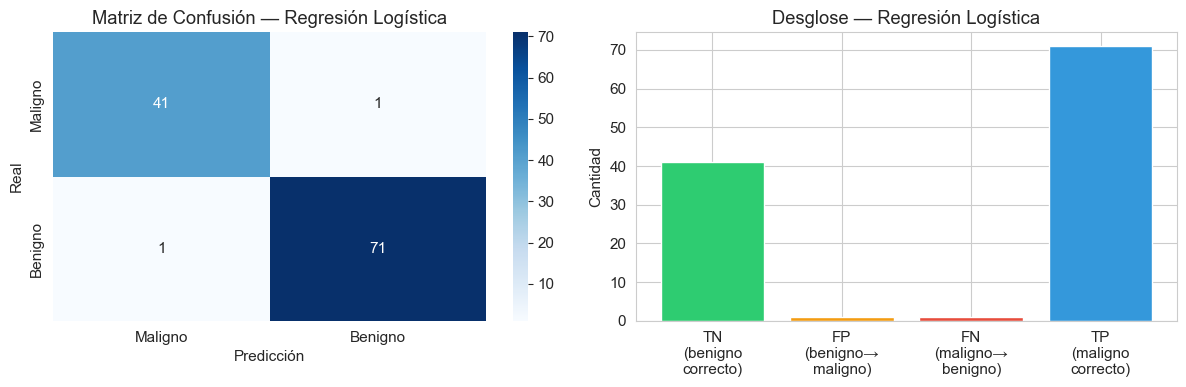


  FN (maligno no detectado): 1
  FP (benigno como maligno): 1

Reporte completo:
              precision    recall  f1-score   support

     maligno       0.98      0.98      0.98        42
     benigno       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [11]:
# 5.2  Evaluación completa
metrics_lr = eval_classifier(pipe_lr, X_train, y_train, X_test, y_test,
                             'Regresión Logística')

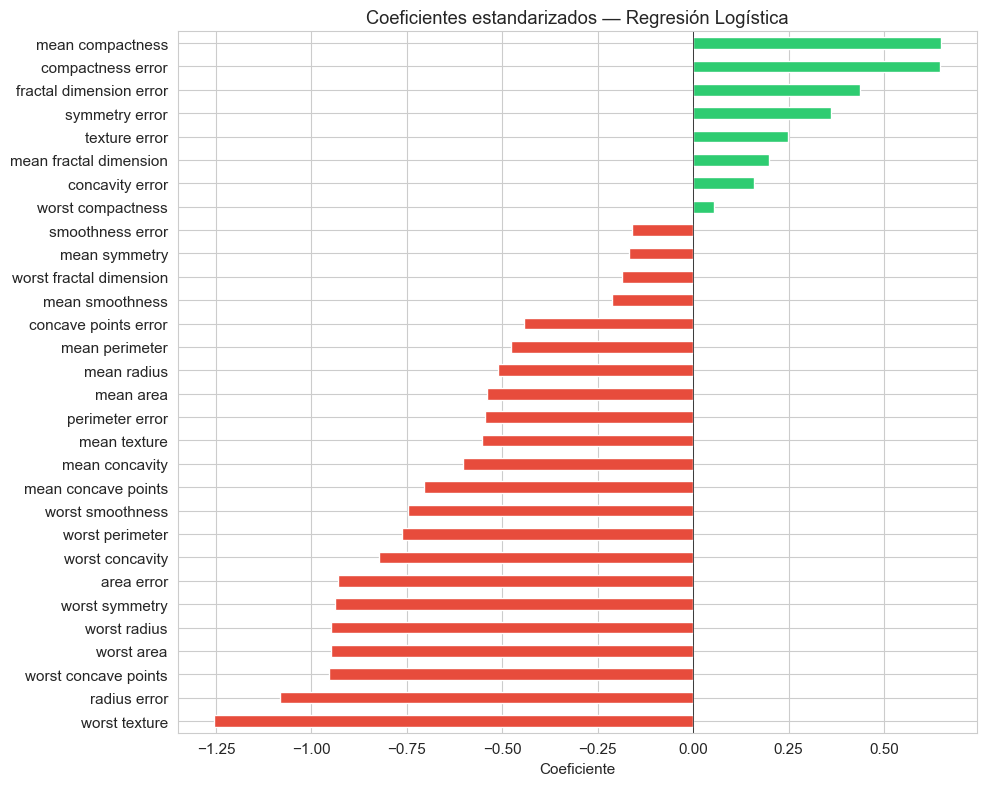

Interpretación:
  → Features que más indican MALIGNO: ['worst texture', 'radius error', 'worst concave points']
  → Features que más indican BENIGNO: ['fractal dimension error', 'compactness error', 'mean compactness']


In [12]:
# 5.3  Coeficientes estandarizados
coefs = pd.Series(
    pipe_lr.named_steps['clf'].coef_[0],
    index=data.feature_names
).sort_values()

fig, ax = plt.subplots(figsize=(10, 8))
colors_bar = ['#e74c3c' if c < 0 else '#2ecc71' for c in coefs]
coefs.plot(kind='barh', ax=ax, color=colors_bar)
ax.set_title('Coeficientes estandarizados — Regresión Logística')
ax.set_xlabel('Coeficiente')
ax.axvline(x=0, color='black', linewidth=0.5)
plt.tight_layout()
plt.show()

print('Interpretación:')
print(f'  → Features que más indican MALIGNO: {coefs.head(3).index.tolist()}')
print(f'  → Features que más indican BENIGNO: {coefs.tail(3).index.tolist()}')

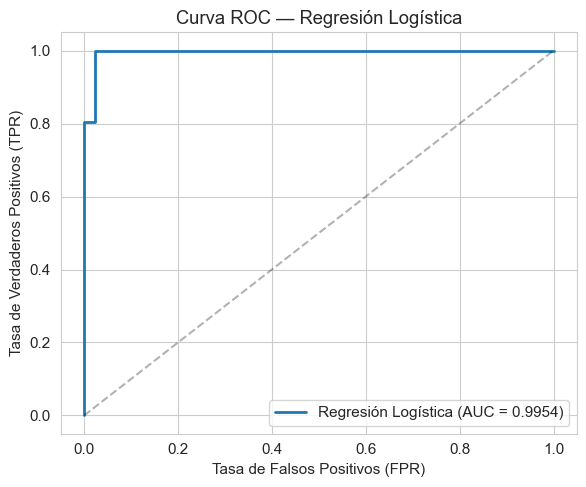

AUC: 0.9954


In [13]:
# 5.4  Curva ROC
fig, ax = plt.subplots(figsize=(6, 5))
auc_lr = plot_roc(pipe_lr, X_test, y_test, 'Regresión Logística', ax)
plt.tight_layout()
plt.show()
print(f'AUC: {auc_lr:.4f}')

---
## 6. Modelo 2 — Árbol de Decisión

**Fundamento:** CART construye particiones recursivas del espacio de features. En cada nodo selecciona la feature y el umbral que maximizan la reducción de impureza (Gini: G(t) = 1 − Σpₖ²). Las particiones son ortogonales a los ejes.

In [14]:
# 6.1  Árbol sin restricciones (para mostrar sobreajuste)
pipe_dt_full = Pipeline([
    ('clf', DecisionTreeClassifier(random_state=42))
])

cv_dt_full = cross_validate(pipe_dt_full, X_train, y_train, cv=skf,
                            scoring=['accuracy', 'f1', 'recall'],
                            return_train_score=True)

print('Árbol de Decisión (SIN restricciones) — CV 5-fold')
print(f'  Train Accuracy: {cv_dt_full["train_accuracy"].mean():.4f}')
print(f'  Test Accuracy:  {cv_dt_full["test_accuracy"].mean():.4f} ± {cv_dt_full["test_accuracy"].std():.4f}')
print(f'  Test F1-Score:  {cv_dt_full["test_f1"].mean():.4f} ± {cv_dt_full["test_f1"].std():.4f}')
print(f'\n⚠ Train accuracy ~1.0 indica sobreajuste')

Árbol de Decisión (SIN restricciones) — CV 5-fold
  Train Accuracy: 1.0000
  Test Accuracy:  0.9165 ± 0.0179
  Test F1-Score:  0.9319 ± 0.0144

⚠ Train accuracy ~1.0 indica sobreajuste


In [15]:
# 6.2  Árbol con pre-poda
pipe_dt = Pipeline([
    ('clf', DecisionTreeClassifier(
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    ))
])

cv_dt = cross_validate(pipe_dt, X_train, y_train, cv=skf,
                       scoring=['accuracy', 'f1', 'recall'],
                       return_train_score=True)

print('Árbol de Decisión (con pre-poda) — CV 5-fold')
print(f'  Train Accuracy: {cv_dt["train_accuracy"].mean():.4f}')
print(f'  Test Accuracy:  {cv_dt["test_accuracy"].mean():.4f} ± {cv_dt["test_accuracy"].std():.4f}')
print(f'  Test F1-Score:  {cv_dt["test_f1"].mean():.4f} ± {cv_dt["test_f1"].std():.4f}')
print(f'  Test Recall:    {cv_dt["test_recall"].mean():.4f} ± {cv_dt["test_recall"].std():.4f}')

pipe_dt.fit(X_train, y_train)
y_pred_dt = pipe_dt.predict(X_test)

Árbol de Decisión (con pre-poda) — CV 5-fold
  Train Accuracy: 0.9747
  Test Accuracy:  0.9275 ± 0.0226
  Test F1-Score:  0.9417 ± 0.0189
  Test Recall:    0.9368 ± 0.0325


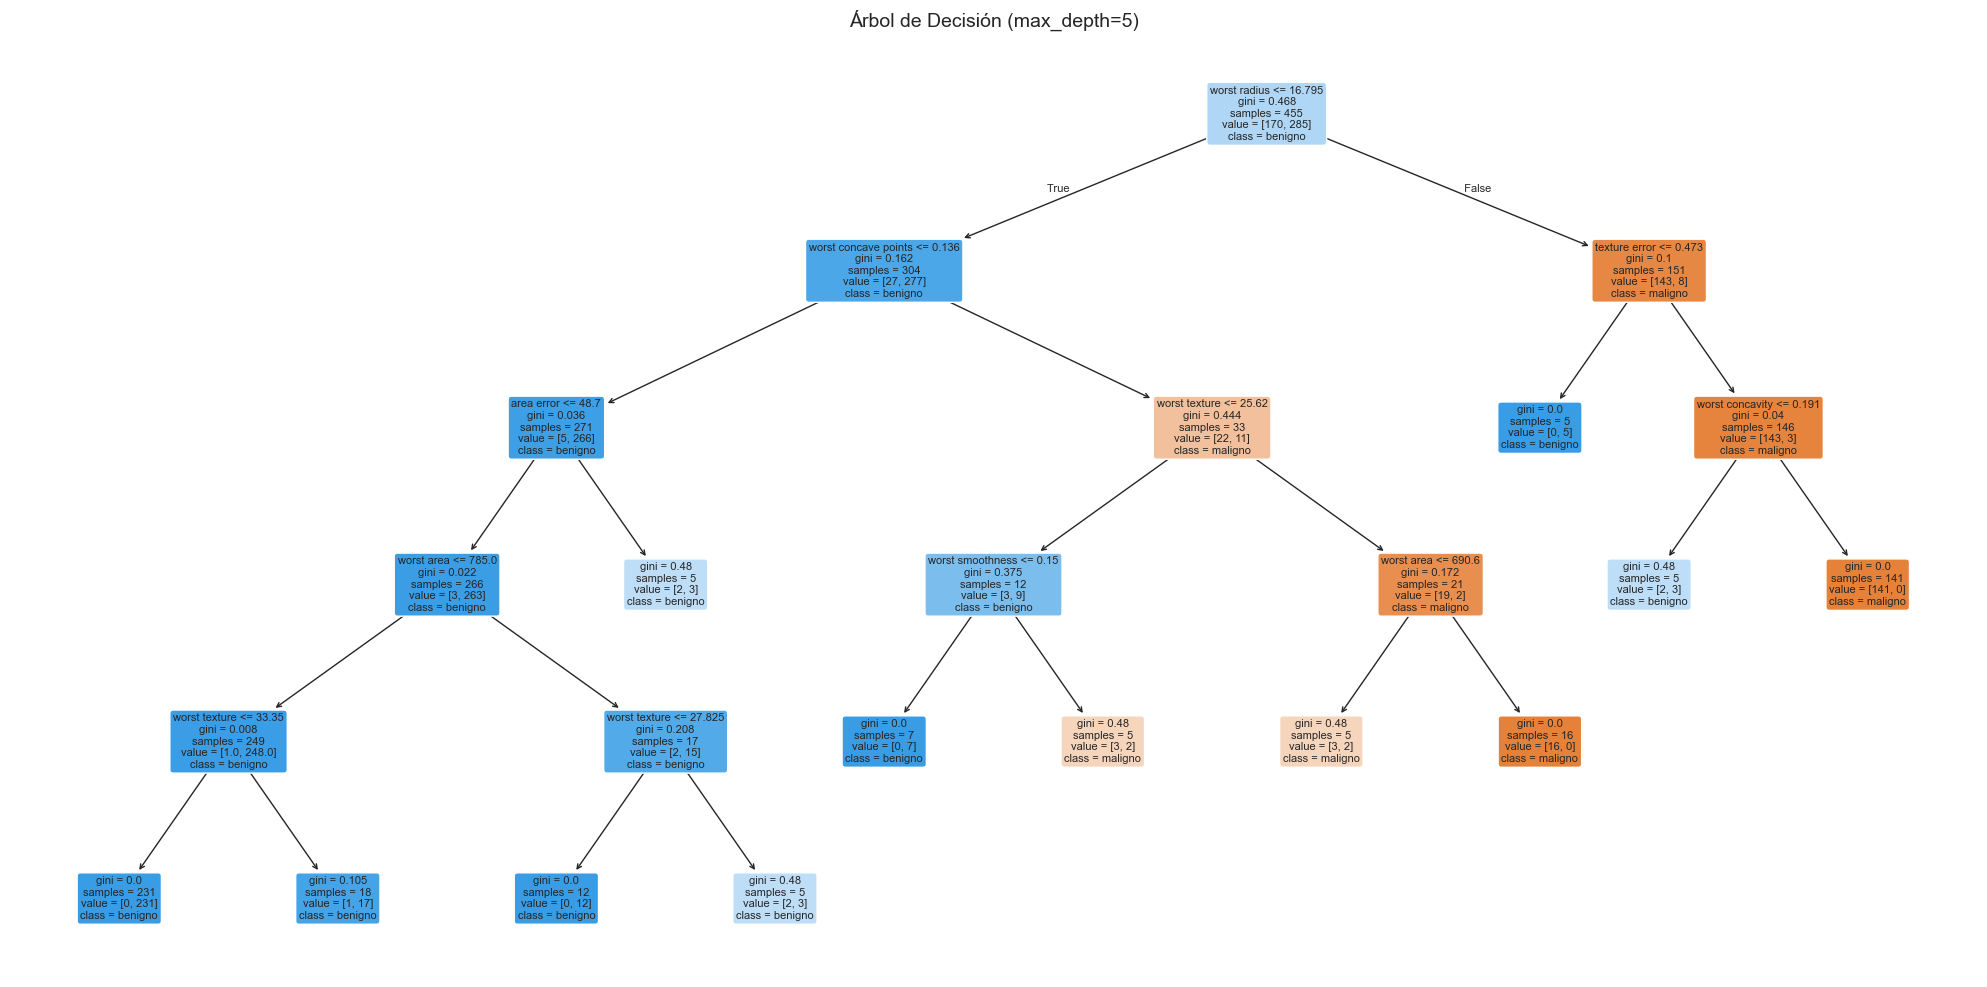

In [16]:
# 6.3  Visualización del árbol podado
fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(pipe_dt.named_steps['clf'],
          feature_names=data.feature_names,
          class_names=['maligno', 'benigno'],
          filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title('Árbol de Decisión (max_depth=5)', fontsize=14)
plt.tight_layout()
plt.show()

=== Árbol de Decisión ===
  Accuracy: 0.9211
  Precision: 0.9437
  Recall: 0.9306
  F1-Score: 0.9371


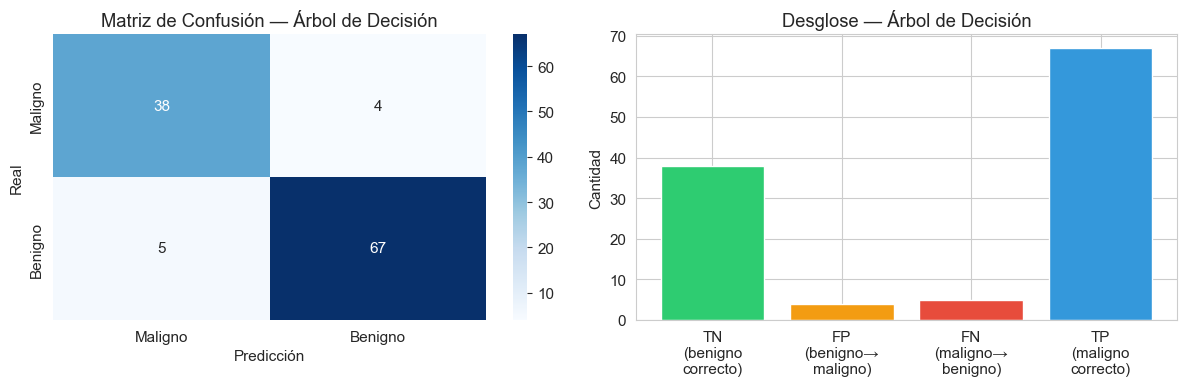


  FN (maligno no detectado): 5
  FP (benigno como maligno): 4

Reporte completo:
              precision    recall  f1-score   support

     maligno       0.88      0.90      0.89        42
     benigno       0.94      0.93      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114



In [17]:
# 6.4  Evaluación completa
metrics_dt = eval_classifier(pipe_dt, X_train, y_train, X_test, y_test,
                             'Árbol de Decisión')

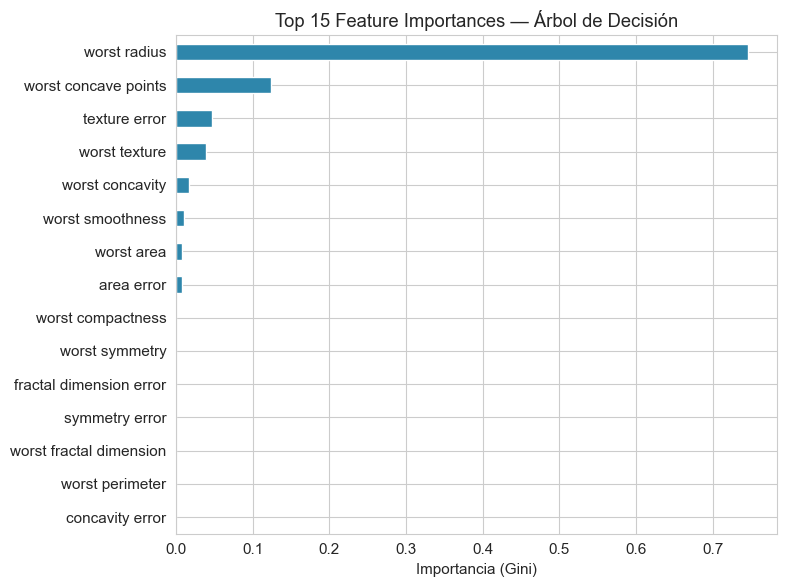

In [18]:
# 6.5  Importancia de features
importances = pd.Series(
    pipe_dt.named_steps['clf'].feature_importances_,
    index=data.feature_names
).sort_values(ascending=True)

# Top 15
top_imp = importances.tail(15)
fig, ax = plt.subplots(figsize=(8, 6))
top_imp.plot(kind='barh', ax=ax, color='#2E86AB')
ax.set_title('Top 15 Feature Importances — Árbol de Decisión')
ax.set_xlabel('Importancia (Gini)')
plt.tight_layout()
plt.show()

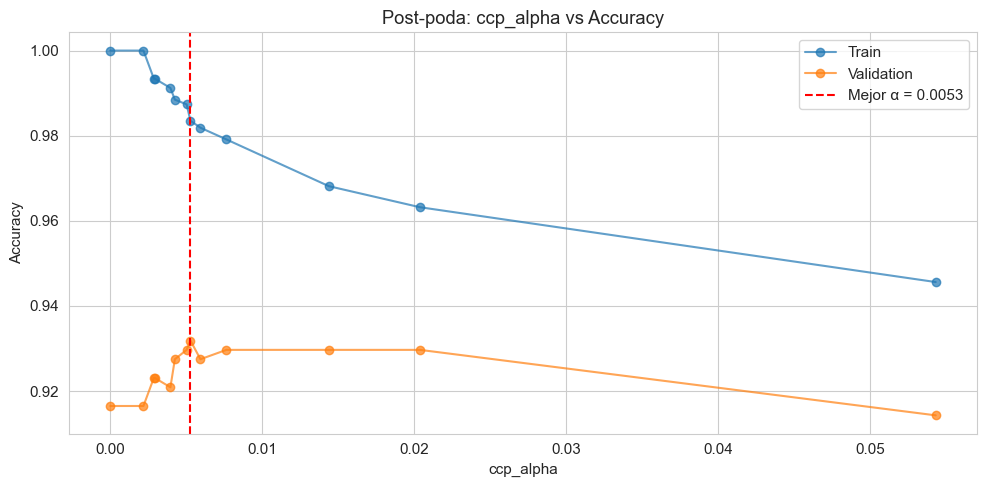

Mejor ccp_alpha: 0.005275


In [19]:
# 6.6  Post-poda con ccp_alpha
path = DecisionTreeClassifier(random_state=42).cost_complexity_pruning_path(X_train, y_train)
alphas = path.ccp_alphas[:-1]  # excluir el último (árbol trivial)

train_scores, test_scores = [], []
for alpha in alphas:
    dt_temp = DecisionTreeClassifier(ccp_alpha=alpha, random_state=42)
    cv_temp = cross_validate(dt_temp, X_train, y_train, cv=skf,
                             scoring='accuracy', return_train_score=True)
    train_scores.append(cv_temp['train_score'].mean())
    test_scores.append(cv_temp['test_score'].mean())

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(alphas, train_scores, 'o-', label='Train', alpha=0.7)
ax.plot(alphas, test_scores, 'o-', label='Validation', alpha=0.7)
best_idx = np.argmax(test_scores)
ax.axvline(x=alphas[best_idx], color='red', linestyle='--',
           label=f'Mejor α = {alphas[best_idx]:.4f}')
ax.set_xlabel('ccp_alpha')
ax.set_ylabel('Accuracy')
ax.set_title('Post-poda: ccp_alpha vs Accuracy')
ax.legend()
plt.tight_layout()
plt.show()
print(f'Mejor ccp_alpha: {alphas[best_idx]:.6f}')

---
## 7. Modelo 3 — Support Vector Machine (SVM)

**Fundamento:** SVM busca el hiperplano de máximo margen γ = 2/‖w‖ que separa las clases. Con margen suave, permite violaciones controladas: min ½‖w‖² + C·Σξᵢ. El kernel trick transforma el espacio para manejar no linealidad.

In [20]:
# 7.1  Pipeline SVM con kernel RBF
pipe_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel='rbf', C=1.0, probability=True, random_state=42))
])

cv_svm = cross_validate(pipe_svm, X_train, y_train, cv=skf,
                        scoring=['accuracy', 'f1', 'recall'],
                        return_train_score=True)

print('SVM (RBF, C=1.0) — CV 5-fold')
print(f'  Accuracy:  {cv_svm["test_accuracy"].mean():.4f} ± {cv_svm["test_accuracy"].std():.4f}')
print(f'  F1-Score:  {cv_svm["test_f1"].mean():.4f} ± {cv_svm["test_f1"].std():.4f}')
print(f'  Recall:    {cv_svm["test_recall"].mean():.4f} ± {cv_svm["test_recall"].std():.4f}')

pipe_svm.fit(X_train, y_train)
y_pred_svm = pipe_svm.predict(X_test)

SVM (RBF, C=1.0) — CV 5-fold
  Accuracy:  0.9692 ± 0.0146
  F1-Score:  0.9756 ± 0.0113
  Recall:    0.9789 ± 0.0131


=== SVM (RBF) ===
  Accuracy: 0.9825
  Precision: 0.9861
  Recall: 0.9861
  F1-Score: 0.9861


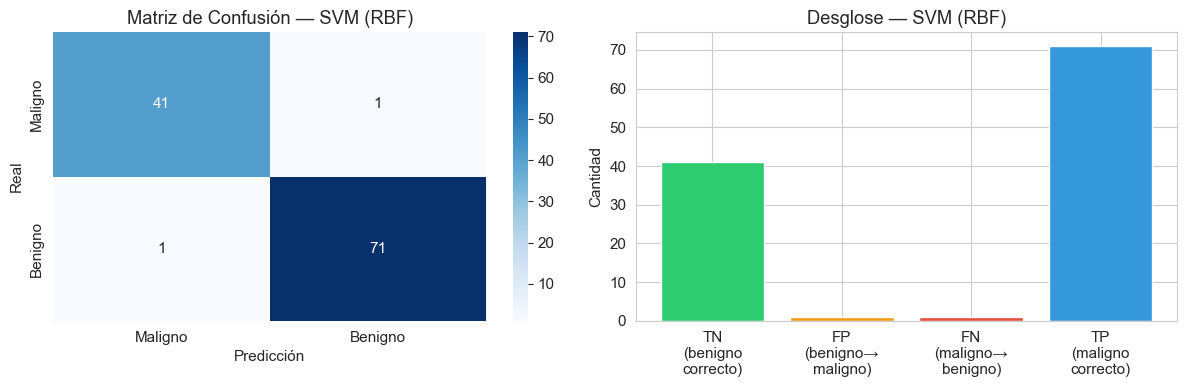


  FN (maligno no detectado): 1
  FP (benigno como maligno): 1

Reporte completo:
              precision    recall  f1-score   support

     maligno       0.98      0.98      0.98        42
     benigno       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [21]:
# 7.2  Evaluación completa
metrics_svm = eval_classifier(pipe_svm, X_train, y_train, X_test, y_test, 'SVM (RBF)')

  Kernel linear  : Accuracy = 0.9648
  Kernel rbf     : Accuracy = 0.9692
  Kernel poly    : Accuracy = 0.8967


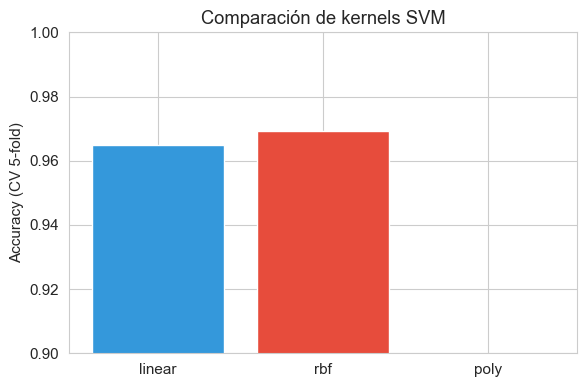

In [22]:
# 7.3  Comparación de kernels
kernels = ['linear', 'rbf', 'poly']
kernel_results = {}

for k in kernels:
    pipe_k = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(kernel=k, C=1.0, probability=True, random_state=42))
    ])
    cv_k = cross_validate(pipe_k, X_train, y_train, cv=skf,
                          scoring='accuracy')
    kernel_results[k] = cv_k['test_score'].mean()
    print(f'  Kernel {k:8s}: Accuracy = {kernel_results[k]:.4f}')

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(kernel_results.keys(), kernel_results.values(), color=['#3498db', '#e74c3c', '#2ecc71'])
ax.set_ylabel('Accuracy (CV 5-fold)')
ax.set_title('Comparación de kernels SVM')
ax.set_ylim(0.9, 1.0)
plt.tight_layout()
plt.show()

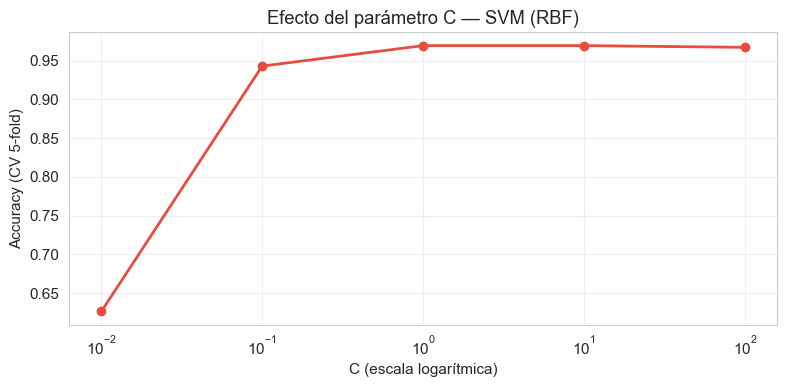


Interpretación:
  C bajo → margen amplio, más errores permitidos (mayor sesgo)
  C alto → margen estrecho, menos errores permitidos (mayor varianza)


In [23]:
# 7.4  Efecto del parámetro C
C_values = [0.01, 0.1, 1, 10, 100]
c_scores = []

for c in C_values:
    pipe_c = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(kernel='rbf', C=c, random_state=42))
    ])
    cv_c = cross_validate(pipe_c, X_train, y_train, cv=skf, scoring='accuracy')
    c_scores.append(cv_c['test_score'].mean())

fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogx(C_values, c_scores, 'o-', color='#e74c3c', linewidth=2)
ax.set_xlabel('C (escala logarítmica)')
ax.set_ylabel('Accuracy (CV 5-fold)')
ax.set_title('Efecto del parámetro C — SVM (RBF)')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('\nInterpretación:')
print('  C bajo → margen amplio, más errores permitidos (mayor sesgo)')
print('  C alto → margen estrecho, menos errores permitidos (mayor varianza)')

---
## 8. Modelo 4 — K-Nearest Neighbors (KNN)

**Fundamento:** Algoritmo de aprendizaje basado en instancias (lazy learning). No construye un modelo explícito; clasifica por voto mayoritario de los K vecinos más cercanos según distancia Euclidiana (por defecto). La regla empírica sugiere K ≈ √n.

In [24]:
# 8.1  Pipeline KNN
pipe_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', KNeighborsClassifier(n_neighbors=5))
])

cv_knn = cross_validate(pipe_knn, X_train, y_train, cv=skf,
                        scoring=['accuracy', 'f1', 'recall'],
                        return_train_score=True)

print('KNN (K=5) — CV 5-fold')
print(f'  Accuracy:  {cv_knn["test_accuracy"].mean():.4f} ± {cv_knn["test_accuracy"].std():.4f}')
print(f'  F1-Score:  {cv_knn["test_f1"].mean():.4f} ± {cv_knn["test_f1"].std():.4f}')
print(f'  Recall:    {cv_knn["test_recall"].mean():.4f} ± {cv_knn["test_recall"].std():.4f}')

pipe_knn.fit(X_train, y_train)
y_pred_knn = pipe_knn.predict(X_test)

KNN (K=5) — CV 5-fold
  Accuracy:  0.9626 ± 0.0112
  F1-Score:  0.9705 ± 0.0091
  Recall:    0.9825 ± 0.0192


=== KNN (K=5) ===
  Accuracy: 0.9561
  Precision: 0.9589
  Recall: 0.9722
  F1-Score: 0.9655


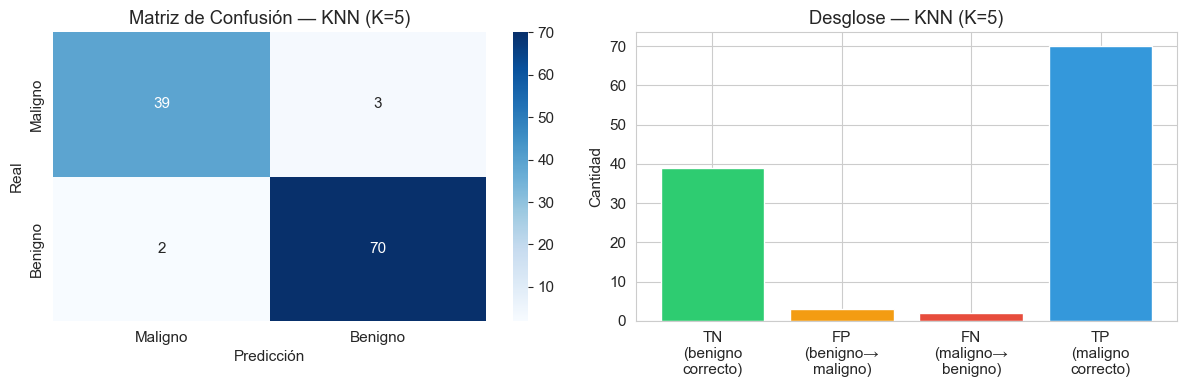


  FN (maligno no detectado): 2
  FP (benigno como maligno): 3

Reporte completo:
              precision    recall  f1-score   support

     maligno       0.95      0.93      0.94        42
     benigno       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [25]:
# 8.2  Evaluación completa
metrics_knn = eval_classifier(pipe_knn, X_train, y_train, X_test, y_test, 'KNN (K=5)')

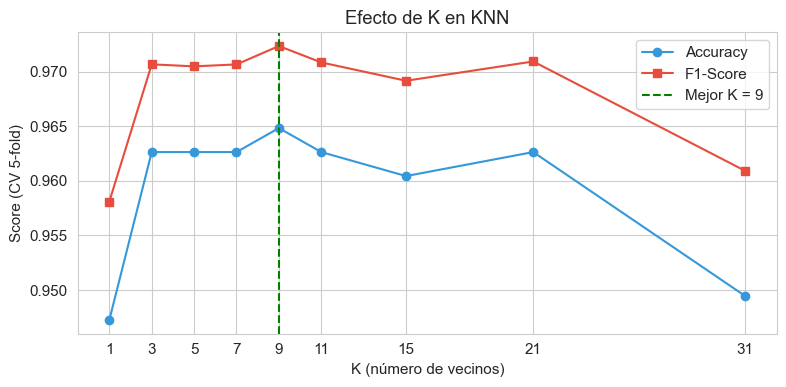

Mejor K por F1: 9
K empírico (√455): 21


In [26]:
# 8.3  Búsqueda del K óptimo
k_values = [1, 3, 5, 7, 9, 11, 15, 21, 31]
k_scores_acc = []
k_scores_f1 = []

for k in k_values:
    pipe_k = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', KNeighborsClassifier(n_neighbors=k))
    ])
    cv_k = cross_validate(pipe_k, X_train, y_train, cv=skf,
                          scoring=['accuracy', 'f1'])
    k_scores_acc.append(cv_k['test_accuracy'].mean())
    k_scores_f1.append(cv_k['test_f1'].mean())

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(k_values, k_scores_acc, 'o-', label='Accuracy', color='#3498db')
ax.plot(k_values, k_scores_f1, 's-', label='F1-Score', color='#e74c3c')
best_k = k_values[np.argmax(k_scores_f1)]
ax.axvline(x=best_k, color='green', linestyle='--', label=f'Mejor K = {best_k}')
ax.set_xlabel('K (número de vecinos)')
ax.set_ylabel('Score (CV 5-fold)')
ax.set_title('Efecto de K en KNN')
ax.legend()
ax.set_xticks(k_values)
plt.tight_layout()
plt.show()

print(f'Mejor K por F1: {best_k}')
print(f'K empírico (√{len(X_train)}): {int(np.sqrt(len(X_train)))}')

In [27]:
# 8.4  Comparación de métricas de distancia
distances = ['euclidean', 'manhattan', 'minkowski']
dist_results = {}

for d in distances:
    p_val = 3 if d == 'minkowski' else 2
    pipe_d = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', KNeighborsClassifier(n_neighbors=5, metric=d, p=p_val))
    ])
    cv_d = cross_validate(pipe_d, X_train, y_train, cv=skf, scoring='f1')
    dist_results[d] = cv_d['test_score'].mean()
    label = f'{d} (p={p_val})' if d == 'minkowski' else d
    print(f'  Distancia {label:20s}: F1 = {dist_results[d]:.4f}')

  Distancia euclidean           : F1 = 0.9705
  Distancia manhattan           : F1 = 0.9705
  Distancia minkowski (p=3)     : F1 = 0.9658


---
## 9. Comparación final de modelos

In [28]:
# 9.1  Tabla resumen de métricas
all_models = {
    'Regresión Logística': pipe_lr,
    'Árbol de Decisión': pipe_dt,
    'SVM (RBF)': pipe_svm,
    'KNN (K=5)': pipe_knn
}

all_metrics = {}
for name, model in all_models.items():
    y_pred = model.predict(X_test)
    if hasattr(model, 'predict_proba'):
        y_prob = model.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        roc_auc_val = auc(fpr, tpr)
    elif hasattr(model, 'decision_function'):
        y_score = model.decision_function(X_test)
        fpr, tpr, _ = roc_curve(y_test, y_score)
        roc_auc_val = auc(fpr, tpr)
    else:
        roc_auc_val = None
    
    all_metrics[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'AUC': roc_auc_val
    }

metrics_df = pd.DataFrame(all_metrics).T.round(4)
print('=== Tabla comparativa de métricas (Test Set) ===')
metrics_df

=== Tabla comparativa de métricas (Test Set) ===


,Accuracy,Precision,Recall,F1-Score,AUC
Regresión Logística,0.9825,0.9861,0.9861,0.9861,0.9954
Árbol de Decisión,0.9211,0.9437,0.9306,0.9371,0.9368
SVM (RBF),0.9825,0.9861,0.9861,0.9861,0.9950
KNN (K=5),0.9561,0.9589,0.9722,0.9655,0.9788


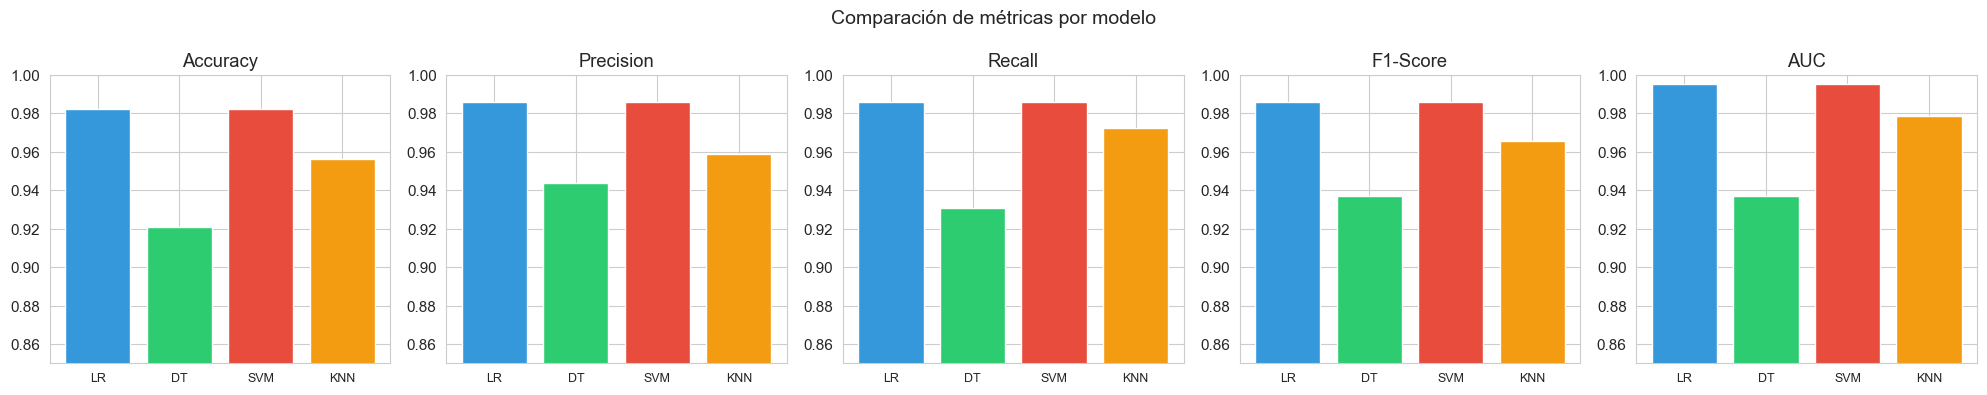

In [29]:
# 9.2  Gráfico de barras comparativo
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC']
colors_models = ['#3498db', '#2ecc71', '#e74c3c', '#f39c12']

for i, metric in enumerate(metric_names):
    values = [all_metrics[m][metric] for m in all_metrics]
    axes[i].bar(range(len(values)), values, color=colors_models)
    axes[i].set_title(metric)
    axes[i].set_ylim(0.85, 1.0)
    axes[i].set_xticks(range(len(values)))
    axes[i].set_xticklabels(['LR', 'DT', 'SVM', 'KNN'], fontsize=9)

plt.suptitle('Comparación de métricas por modelo', fontsize=14)
plt.tight_layout()
plt.show()

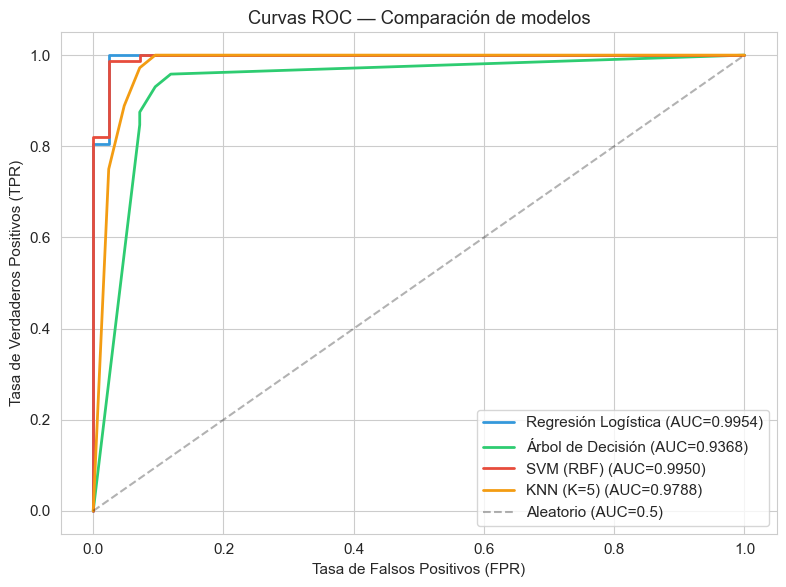

In [30]:
# 9.3  Curvas ROC superpuestas
fig, ax = plt.subplots(figsize=(8, 6))

for (name, model), color in zip(all_models.items(), colors_models):
    if hasattr(model, 'predict_proba'):
        y_prob = model.predict_proba(X_test)[:, 1]
    elif hasattr(model, 'decision_function'):
        y_prob = model.decision_function(X_test)
    else:
        continue
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc_val = auc(fpr, tpr)
    ax.plot(fpr, tpr, linewidth=2, color=color,
            label=f'{name} (AUC={roc_auc_val:.4f})')

ax.plot([0, 1], [0, 1], 'k--', alpha=0.3, label='Aleatorio (AUC=0.5)')
ax.set_xlabel('Tasa de Falsos Positivos (FPR)')
ax.set_ylabel('Tasa de Verdaderos Positivos (TPR)')
ax.set_title('Curvas ROC — Comparación de modelos')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [31]:
# 9.4  Matriz de selección
selection_matrix = pd.DataFrame({
    'Modelo': ['Reg. Logística', 'Árbol de Decisión', 'SVM (RBF)', 'KNN'],
    'Precisión predictiva': ['★★★★☆', '★★★☆☆', '★★★★★', '★★★★☆'],
    'Velocidad (train+pred)': ['★★★★★', '★★★★☆', '★★★☆☆', '★★★★★'],
    'Interpretabilidad': ['★★★★☆', '★★★★★', '★★☆☆☆', '★★★☆☆'],
    'Escalabilidad': ['★★★★★', '★★★★☆', '★★☆☆☆', '★★☆☆☆'],
    'Robustez a outliers': ['★★★☆☆', '★★★★☆', '★★★★☆', '★★☆☆☆']
}).set_index('Modelo')

print('=== Matriz de Selección de Modelos ===')
selection_matrix

=== Matriz de Selección de Modelos ===


,Precisión predictiva,Velocidad (train+pred),Interpretabilidad,Escalabilidad,Robustez a outliers
Modelo,,,,,
Reg. Logística,★★★★☆,★★★★★,★★★★☆,★★★★★,★★★☆☆
Árbol de Decisión,★★★☆☆,★★★★☆,★★★★★,★★★★☆,★★★★☆
SVM (RBF),★★★★★,★★★☆☆,★★☆☆☆,★★☆☆☆,★★★★☆
KNN,★★★★☆,★★★★★,★★★☆☆,★★☆☆☆,★★☆☆☆


---
## 10. Resumen comparativo

| Modelo | Fortalezas | Limitaciones | ¿Cuándo usarlo? |
|---|---|---|---|
| **Reg. Logística** | Interpretable, probabilístico, rápido | Asume linealidad en log-odds | Clasificación binaria con necesidad de interpretabilidad |
| **Árbol de Decisión** | Explicable, maneja tipos mixtos | Propenso a sobreajuste sin poda | Reglas de negocio, explicabilidad ante stakeholders |
| **SVM** | Efectivo en alta dimensión, robusto al ruido | Lento con muchos datos, difícil de interpretar | Datasets de dimensión media-alta, márgenes claros |
| **KNN** | Simple, no paramétrico, flexible | Lento en predicción, maldición de la dimensionalidad | Datasets pequeños-medianos con features normalizadas |

**Criterio de selección final:** En este dataset médico, **Recall** es la métrica prioritaria (minimizar falsos negativos). El modelo con mejor Recall en test es el candidato preferido para despliegue.

---
## 11. Ejercicios propuestos

### Ejercicio 1 — Optimización con GridSearchCV
Para cada modelo, realice una búsqueda exhaustiva de hiperparámetros con `GridSearchCV(cv=5, scoring='f1')`. Parámetros sugeridos:
- **LogisticRegression:** C=[0.01, 0.1, 1, 10, 100]
- **DecisionTree:** max_depth=[3,5,7,10,None], min_samples_leaf=[1,5,10]
- **SVM:** C=[0.1,1,10], gamma=[0.001,0.01,0.1]
- **KNN:** n_neighbors=[3,5,9,15,21], weights=['uniform','distance']

Compare los mejores modelos optimizados.

### Ejercicio 2 — Manejo de desbalance con class_weight y SMOTE
Entrene los 4 modelos con `class_weight='balanced'`. Compare Recall de la clase maligna con y sin balanceo. Además, aplique SMOTE:
```python
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_train, y_train)
```

### Ejercicio 3 — Dataset propio
Seleccione un dataset de clasificación de Kaggle/UCI (mín. 500 registros, 5 features). Aplique los 4 modelos + al menos 1 adicional (Random Forest, Gradient Boosting o Naive Bayes). Documente métricas, curvas ROC, matriz de selección y justificación del mejor modelo.

---
*Ingeniería del Conocimiento (ISO56B) — UNCP — 2026-II*

---
## 11. Ejercicios propuestos

### Ejercicio 1 — Optimización con GridSearchCV
Para cada modelo, realice una búsqueda exhaustiva de hiperparámetros con `GridSearchCV(cv=5, scoring='f1')`. Parámetros sugeridos:
- **LogisticRegression:** C=[0.01, 0.1, 1, 10, 100]
- **DecisionTree:** max_depth=[3,5,7,10,None], min_samples_leaf=[1,5,10]
- **SVM:** C=[0.1,1,10], gamma=[0.001,0.01,0.1]
- **KNN:** n_neighbors=[3,5,9,15,21], weights=['uniform','distance']

In [32]:
from sklearn.model_selection import GridSearchCV
import time

# Pipelines base (sin hiperparámetros fijos)
pipe_lr_gs = Pipeline([('scaler', StandardScaler()),
                       ('clf', LogisticRegression(max_iter=1000, random_state=42))])

pipe_dt_gs = Pipeline([('clf', DecisionTreeClassifier(random_state=42))])

pipe_svm_gs = Pipeline([('scaler', StandardScaler()),
                        ('clf', SVC(probability=True, random_state=42))])

pipe_knn_gs = Pipeline([('scaler', StandardScaler()),
                        ('clf', KNeighborsClassifier())])

# Grillas sugeridas
grids = {
    'Regresión Logística': {
        'estimator': pipe_lr_gs,
        'param_grid': {'clf__C': [0.01, 0.1, 1, 10, 100]}
    },
    'Árbol de Decisión': {
        'estimator': pipe_dt_gs,
        'param_grid': {'clf__max_depth': [3, 5, 7, 10, None],
                       'clf__min_samples_leaf': [1, 5, 10]}
    },
    'SVM (RBF)': {
        'estimator': pipe_svm_gs,
        'param_grid': {'clf__C': [0.1, 1, 10],
                       'clf__gamma': [0.001, 0.01, 0.1]}
    },
    'KNN': {
        'estimator': pipe_knn_gs,
        'param_grid': {'clf__n_neighbors': [3, 5, 9, 15, 21],
                       'clf__weights': ['uniform', 'distance']}
    }
}

print("Grillas definidas para los 4 modelos ✓")

Grillas definidas para los 4 modelos ✓


In [33]:
grid_results = {}

for name, cfg in grids.items():
    t0 = time.time()
    gs = GridSearchCV(
        estimator=cfg['estimator'],
        param_grid=cfg['param_grid'],
        cv=skf,                  # StratifiedKFold ya definido
        scoring='f1',            # F1 de clase 1 (benigno)
        n_jobs=-1,
        refit=True
    )
    gs.fit(X_train, y_train)
    t = time.time() - t0

    grid_results[name] = gs
    print(f"{name:22s} | mejor F1 = {gs.best_score_:.4f} | "
          f"{len(gs.cv_results_['params'])} combos | {t:.1f}s")
    print(f"   mejores params: {gs.best_params_}")

Regresión Logística    | mejor F1 = 0.9861 | 5 combos | 5.8s
   mejores params: {'clf__C': 0.1}
Árbol de Decisión      | mejor F1 = 0.9460 | 15 combos | 0.3s
   mejores params: {'clf__max_depth': 3, 'clf__min_samples_leaf': 5}
SVM (RBF)              | mejor F1 = 0.9810 | 9 combos | 0.2s
   mejores params: {'clf__C': 10, 'clf__gamma': 0.01}
KNN                    | mejor F1 = 0.9724 | 10 combos | 0.3s
   mejores params: {'clf__n_neighbors': 9, 'clf__weights': 'uniform'}


In [34]:
# Recolectar métricas sobre test (incluyendo recall de malignos)
comparison = []
for name, gs in grid_results.items():
    y_pred = gs.predict(X_test)
    comparison.append({
        'Modelo': name,
        'Mejor F1 (CV)': round(gs.best_score_, 4),
        'Accuracy (test)': round(accuracy_score(y_test, y_pred), 4),
        'F1 (test)': round(f1_score(y_test, y_pred), 4),
        'Recall maligno': round(recall_score(y_test, y_pred, pos_label=0), 4)
    })

comp_df = pd.DataFrame(comparison).sort_values('Mejor F1 (CV)', ascending=False)
print("=== Comparación de modelos optimizados ===")
comp_df

=== Comparación de modelos optimizados ===


,Modelo,Mejor F1 (CV),Accuracy (test),F1 (test),Recall maligno
0,Regresión Logística,0.9861,0.9737,0.9793,0.9524
2,SVM (RBF),0.9810,0.9825,0.9861,0.9762
3,KNN,0.9724,0.9737,0.9796,0.9286
1,Árbol de Decisión,0.9460,0.9386,0.9517,0.9048


---
### Ejercicio 2 — Manejo de desbalance con class_weight y SMOTE
Entrene los 4 modelos con `class_weight='balanced'`. Compare Recall de la clase maligna con y sin balanceo. Además, aplique SMOTE:
```python
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_train, y_train)
```

In [35]:
# Reentrenamos los 4 pipelines SIN balanceo para tener baseline limpio
baseline_models = {
    'LR':  Pipeline([('scaler', StandardScaler()),
                     ('clf', LogisticRegression(max_iter=1000, random_state=42))]),
    'DT':  Pipeline([('clf', DecisionTreeClassifier(max_depth=5, min_samples_leaf=5,
                                                    random_state=42))]),
    'SVM': Pipeline([('scaler', StandardScaler()),
                     ('clf', SVC(kernel='rbf', C=1.0, random_state=42))]),
    'KNN': Pipeline([('scaler', StandardScaler()),
                     ('clf', KNeighborsClassifier(n_neighbors=5))])
}

def evaluate_recall(model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    return {
        'Accuracy': accuracy_score(y_te, y_pred),
        'Recall maligno': recall_score(y_te, y_pred, pos_label=0),
        'Recall benigno': recall_score(y_te, y_pred, pos_label=1)
    }

baseline_results = {}
for name, m in baseline_models.items():
    baseline_results[name] = evaluate_recall(m, X_train, y_train, X_test, y_test)

pd.DataFrame(baseline_results).T.round(4)

,Accuracy,Recall maligno,Recall benigno
LR,0.9825,0.9762,0.9861
DT,0.9211,0.9048,0.9306
SVM,0.9825,0.9762,0.9861
KNN,0.9561,0.9286,0.9722


In [36]:
balanced_models = {
    'LR':  Pipeline([('scaler', StandardScaler()),
                     ('clf', LogisticRegression(max_iter=1000, random_state=42,
                                                class_weight='balanced'))]),
    'DT':  Pipeline([('clf', DecisionTreeClassifier(max_depth=5, min_samples_leaf=5,
                                                    random_state=42,
                                                    class_weight='balanced'))]),
    'SVM': Pipeline([('scaler', StandardScaler()),
                     ('clf', SVC(kernel='rbf', C=1.0, random_state=42,
                                 class_weight='balanced'))]),
    'KNN': None  # KNN no acepta class_weight
}

balanced_results = {}
for name, m in balanced_models.items():
    if m is None:
        balanced_results[name] = {'Accuracy': np.nan,
                                  'Recall maligno': np.nan,
                                  'Recall benigno': np.nan}
    else:
        balanced_results[name] = evaluate_recall(m, X_train, y_train, X_test, y_test)

pd.DataFrame(balanced_results).T.round(4)

,Accuracy,Recall maligno,Recall benigno
LR,0.9561,0.9762,0.9444
DT,0.9123,0.9048,0.9167
SVM,0.9649,0.9762,0.9583
KNN,NaN,NaN,NaN


In [37]:
from imblearn.over_sampling import SMOTE
from sklearn.base import clone 

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print(f"Antes  → {np.bincount(y_train)}  (maligno / benigno)")
print(f"Después → {np.bincount(y_train_res)}  (maligno / benigno)")

# Entrenar los mismos 4 modelos sobre datos balanceados con SMOTE
smote_results = {}
for name, m in baseline_models.items():
    # Reutilizamos pipelines "vacíos" para reentrenar
    model_copy = clone(m)
    smote_results[name] = evaluate_recall(model_copy, X_train_res, y_train_res,
                                          X_test, y_test)

pd.DataFrame(smote_results).T.round(4)

Antes  → [170 285]  (maligno / benigno)
Después → [285 285]  (maligno / benigno)


,Accuracy,Recall maligno,Recall benigno
LR,0.9649,0.9762,0.9583
DT,0.9386,0.9286,0.9444
SVM,0.9825,0.9762,0.9861
KNN,0.9123,0.9524,0.8889


In [38]:
# Consolidar en una tabla: Recall maligno por modelo y estrategia
resumen = pd.DataFrame({
    'Baseline':        {k: baseline_results[k]['Recall maligno'] for k in baseline_results},
    'class_weight':    {k: balanced_results[k]['Recall maligno'] for k in balanced_results},
    'SMOTE':           {k: smote_results[k]['Recall maligno']     for k in smote_results}
}).round(4)

print("=== Recall de la clase MALIGNA según estrategia ===")
resumen

=== Recall de la clase MALIGNA según estrategia ===


,Baseline,class_weight,SMOTE
LR,0.9762,0.9762,0.9762
DT,0.9048,0.9048,0.9286
SVM,0.9762,0.9762,0.9762
KNN,0.9286,NaN,0.9524


---
### Ejercicio 3 — Dataset propio
Seleccione un dataset de clasificación de Kaggle/UCI (mín. 500 registros, 5 features). Aplique los 4 modelos + al menos 1 adicional (Random Forest, Gradient Boosting o Naive Bayes). Documente métricas, curvas ROC, matriz de selección y justificación del mejor modelo.

---
**Dataset:** `Cleaned_Viral_Social_Media_Trends.csv` (5000 registros, 11 columnas)

**Target (Escenario A):** `Engagement_Level` binarizado → **High (1)** vs **{Medium, Low} (0)**

**Features:** variables contextuales de la publicación (Platform, Hashtag, Content_Type, Region, año, mes, día de semana).

**Decisión de diseño:** se excluyen `Views`, `Likes`, `Shares`, `Comments` y `Post_ID` para **evitar data leakage**, ya que `Engagement_Level` es derivado de ellas. El objetivo es predecir el nivel de engagement a partir del **contexto** de publicación, no de sus métricas.

In [39]:
# 12.1  Carga y preparación del dataset
df_v = pd.read_csv('Cleaned_Viral_Social_Media_Trends.csv')

print(f'Dataset: {df_v.shape[0]} filas, {df_v.shape[1]} columnas')
print(f'\nDistribución original de Engagement_Level:')
print(df_v['Engagement_Level'].value_counts())
print(f'\nValores nulos por columna:')
print(df_v.isnull().sum().sum(), 'nulos en total')

# --- Target binario: High (1) vs {Medium, Low} (0) ---
df_v['target'] = (df_v['Engagement_Level'] == 'High').astype(int)

print(f'\nTarget binario:')
print(df_v['target'].value_counts())
print(f'Proporción High: {df_v["target"].mean():.2%}')

# --- Fecha → features temporales ---
df_v['Post_Date'] = pd.to_datetime(df_v['Post_Date'])
df_v['year']  = df_v['Post_Date'].dt.year
df_v['month'] = df_v['Post_Date'].dt.month
df_v['dow']   = df_v['Post_Date'].dt.dayofweek  # 0=lunes, 6=domingo

df_v[['Post_Date','year','month','dow','target']].head()

Dataset: 5000 filas, 11 columnas

Distribución original de Engagement_Level:
Engagement_Level
Low       1729
High      1673
Medium    1598
Name: count, dtype: int64

Valores nulos por columna:
0 nulos en total

Target binario:
target
0    3327
1    1673
Name: count, dtype: int64
Proporción High: 33.46%


,Post_Date,year,month,dow,target
0,2022-01-13,2022,1,3,1
1,2022-05-13,2022,5,4,0
2,2022-01-07,2022,1,4,0
3,2022-12-05,2022,12,0,0
4,2023-03-23,2023,3,3,0


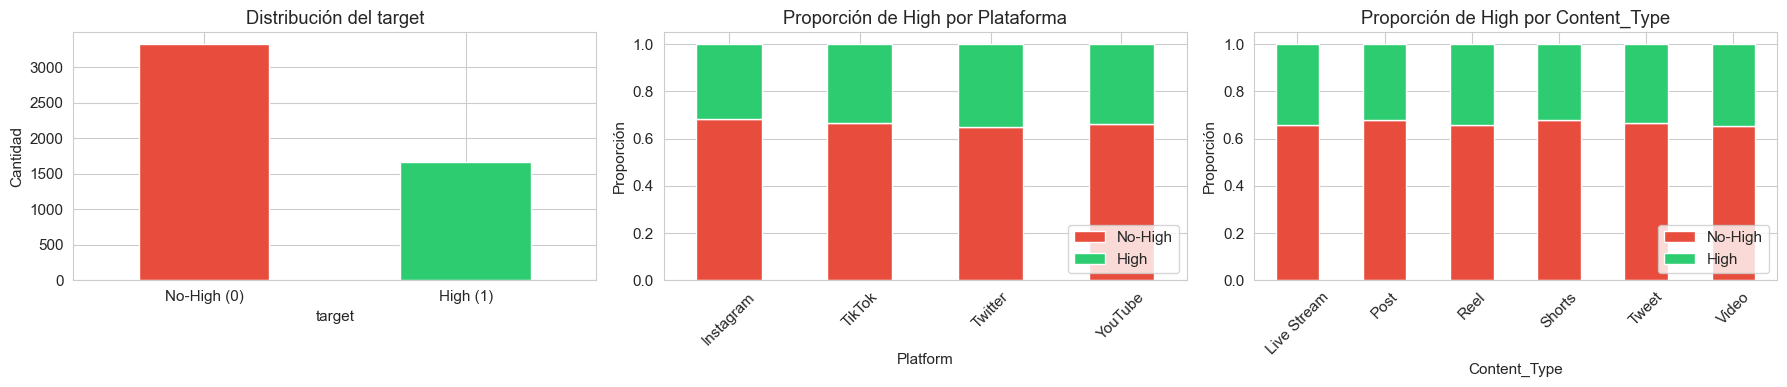

In [40]:
# 12.2  EDA orientado a clasificación
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# Distribución del target
df_v['target'].value_counts().plot(
    kind='bar', ax=axes[0], color=['#e74c3c','#2ecc71'])
axes[0].set_title('Distribución del target')
axes[0].set_xticklabels(['No-High (0)', 'High (1)'], rotation=0)
axes[0].set_ylabel('Cantidad')

# Engagement por plataforma
pd.crosstab(df_v['Platform'], df_v['target'], normalize='index').plot(
    kind='bar', stacked=True, ax=axes[1],
    color=['#e74c3c','#2ecc71'])
axes[1].set_title('Proporción de High por Plataforma')
axes[1].set_ylabel('Proporción')
axes[1].legend(['No-High', 'High'], loc='lower right')
axes[1].tick_params(axis='x', rotation=45)

# Engagement por Content_Type
pd.crosstab(df_v['Content_Type'], df_v['target'], normalize='index').plot(
    kind='bar', stacked=True, ax=axes[2],
    color=['#e74c3c','#2ecc71'])
axes[2].set_title('Proporción de High por Content_Type')
axes[2].set_ylabel('Proporción')
axes[2].legend(['No-High', 'High'], loc='lower right')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [41]:
# 12.3  Preparación de X, y y split estratificado
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

cat_features = ['Platform', 'Hashtag', 'Content_Type', 'Region']
num_features = ['year', 'month', 'dow']

X_v = df_v[cat_features + num_features].copy()
y_v = df_v['target'].copy()

X_tr, X_te, y_tr, y_te = train_test_split(
    X_v, y_v, test_size=0.2, random_state=42, stratify=y_v
)

print(f'Train: {X_tr.shape[0]} | Test: {X_te.shape[0]}')
print(f'Proporción High en train: {y_tr.mean():.2%}')
print(f'Proporción High en test:  {y_te.mean():.2%}')

# Preprocesador común (OHE para categóricas + escalado para numéricas)
preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features),
    ('num', StandardScaler(), num_features)
])

# Scorer con pos_label=1 (High) — coherente con el target elegido
scoring_multi = {
    'accuracy': 'accuracy',
    'f1': 'f1',
    'recall': 'recall',
    'precision': 'precision'
}

Train: 4000 | Test: 1000
Proporción High en train: 33.45%
Proporción High en test:  33.50%


In [42]:
# 12.4  Definición de los 5 modelos
modelos_v = {
    'Regresión Logística': Pipeline([
        ('pre', preprocessor),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'Árbol de Decisión': Pipeline([
        ('pre', preprocessor),
        ('clf', DecisionTreeClassifier(max_depth=6, min_samples_leaf=10,
                                       random_state=42))
    ]),
    'SVM (RBF)': Pipeline([
        ('pre', preprocessor),
        ('clf', SVC(kernel='rbf', C=1.0, probability=True, random_state=42))
    ]),
    'KNN (K=5)': Pipeline([
        ('pre', preprocessor),
        ('clf', KNeighborsClassifier(n_neighbors=5))
    ]),
    'Random Forest': Pipeline([
        ('pre', preprocessor),
        ('clf', RandomForestClassifier(n_estimators=200, max_depth=10,
                                       random_state=42, n_jobs=-1))
    ])
}

# --- Validación cruzada ---
skf_v = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print('=== Cross-Validation (5-fold) sobre train ===')
cv_results_v = {}
for nombre, modelo in modelos_v.items():
    cv = cross_validate(modelo, X_tr, y_tr, cv=skf_v,
                        scoring=scoring_multi, n_jobs=-1)
    cv_results_v[nombre] = {
        'Accuracy': cv['test_accuracy'].mean(),
        'Precision': cv['test_precision'].mean(),
        'Recall':   cv['test_recall'].mean(),
        'F1':       cv['test_f1'].mean()
    }
    print(f'{nombre:22s} | Acc={cv["test_accuracy"].mean():.4f} | '
          f'F1={cv["test_f1"].mean():.4f} | Rec={cv["test_recall"].mean():.4f}')

print('\n=== Entrenamiento sobre train completo ===')
for nombre, modelo in modelos_v.items():
    modelo.fit(X_tr, y_tr)
print('Modelos entrenados ✓')

=== Cross-Validation (5-fold) sobre train ===
Regresión Logística    | Acc=0.6655 | F1=0.0000 | Rec=0.0000
Árbol de Decisión      | Acc=0.6520 | F1=0.0384 | Rec=0.0209
SVM (RBF)              | Acc=0.6655 | F1=0.0000 | Rec=0.0000
KNN (K=5)              | Acc=0.5938 | F1=0.2586 | Rec=0.2123
Random Forest          | Acc=0.6645 | F1=0.0059 | Rec=0.0030

=== Entrenamiento sobre train completo ===
Modelos entrenados ✓


In [43]:
# 12.5  Comparación de métricas en test
all_metrics_v = {}
for nombre, modelo in modelos_v.items():
    y_pred = modelo.predict(X_te)
    y_prob = modelo.predict_proba(X_te)[:, 1]
    fpr, tpr, _ = roc_curve(y_te, y_prob)

    all_metrics_v[nombre] = {
        'Accuracy':  accuracy_score(y_te, y_pred),
        'Precision': precision_score(y_te, y_pred),
        'Recall':    recall_score(y_te, y_pred),
        'F1-Score':  f1_score(y_te, y_pred),
        'AUC':       auc(fpr, tpr)
    }

metrics_v_df = pd.DataFrame(all_metrics_v).T.round(4)
print('=== Tabla comparativa (Test Set) ===')
metrics_v_df.sort_values('F1-Score', ascending=False)

=== Tabla comparativa (Test Set) ===


,Accuracy,Precision,Recall,F1-Score,AUC
KNN (K=5),0.598,0.3456,0.2239,0.2717,0.5197
Árbol de Decisión,0.656,0.3200,0.0239,0.0444,0.5037
Regresión Logística,0.665,0.0000,0.0000,0.0000,0.4891
SVM (RBF),0.665,0.0000,0.0000,0.0000,0.4828
Random Forest,0.662,0.0000,0.0000,0.0000,0.4935


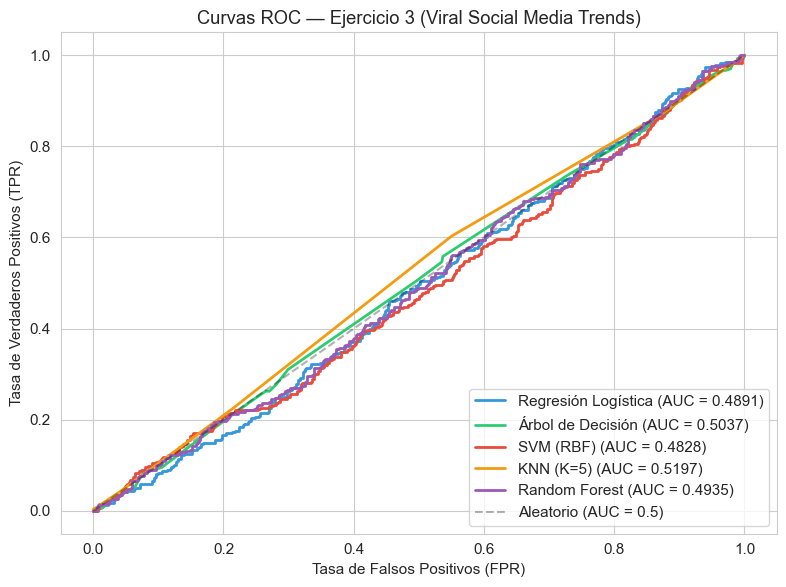

In [44]:
# 12.6  Curvas ROC — Comparación
fig, ax = plt.subplots(figsize=(8, 6))
colores_v = ['#3498db', '#2ecc71', '#e74c3c', '#f39c12', '#9b59b6']

for (nombre, modelo), color in zip(modelos_v.items(), colores_v):
    y_prob = modelo.predict_proba(X_te)[:, 1]
    fpr, tpr, _ = roc_curve(y_te, y_prob)
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, linewidth=2, color=color,
            label=f'{nombre} (AUC = {roc_auc:.4f})')

ax.plot([0, 1], [0, 1], 'k--', alpha=0.3, label='Aleatorio (AUC = 0.5)')
ax.set_xlabel('Tasa de Falsos Positivos (FPR)')
ax.set_ylabel('Tasa de Verdaderos Positivos (TPR)')
ax.set_title('Curvas ROC — Ejercicio 3 (Viral Social Media Trends)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

Mejor modelo por F1 en test: KNN (K=5)


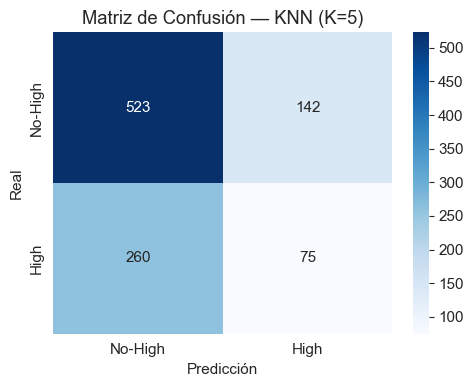


Reporte de clasificación:
              precision    recall  f1-score   support

     No-High       0.67      0.79      0.72       665
        High       0.35      0.22      0.27       335

    accuracy                           0.60      1000
   macro avg       0.51      0.51      0.50      1000
weighted avg       0.56      0.60      0.57      1000



In [45]:
# 12.7  Matriz de confusión del mejor modelo (por F1 en test)
mejor_nombre = metrics_v_df['F1-Score'].idxmax()
mejor_modelo = modelos_v[mejor_nombre]
print(f'Mejor modelo por F1 en test: {mejor_nombre}')

y_pred_best = mejor_modelo.predict(X_te)

fig, ax = plt.subplots(figsize=(5, 4))
cm = confusion_matrix(y_te, y_pred_best)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['No-High', 'High'],
            yticklabels=['No-High', 'High'])
ax.set_title(f'Matriz de Confusión — {mejor_nombre}')
ax.set_xlabel('Predicción')
ax.set_ylabel('Real')
plt.tight_layout()
plt.show()

print(f'\nReporte de clasificación:')
print(classification_report(y_te, y_pred_best,
      target_names=['No-High', 'High']))

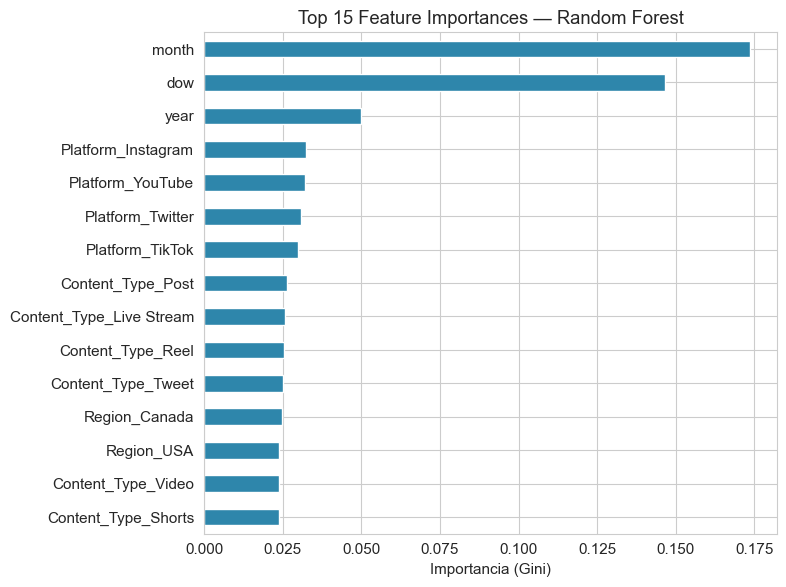

In [46]:
# 12.8  Top features del Random Forest
rf_pipe = modelos_v['Random Forest']
ohe = rf_pipe.named_steps['pre'].named_transformers_['cat']
cat_names = ohe.get_feature_names_out(cat_features)
feat_names = list(cat_names) + num_features

importances = pd.Series(
    rf_pipe.named_steps['clf'].feature_importances_,
    index=feat_names
).sort_values(ascending=True).tail(15)

fig, ax = plt.subplots(figsize=(8, 6))
importances.plot(kind='barh', ax=ax, color='#2E86AB')
ax.set_title('Top 15 Feature Importances — Random Forest')
ax.set_xlabel('Importancia (Gini)')
plt.tight_layout()
plt.show()

In [47]:
# 12.9  Matriz de selección cualitativa
selection_v = pd.DataFrame({
    'Modelo': ['Reg. Logística', 'Árbol de Decisión', 'SVM (RBF)',
               'KNN', 'Random Forest'],
    'Precisión predictiva':  ['★★★★☆','★★★☆☆','★★★★☆','★★★☆☆','★★★★★'],
    'Velocidad (train+pred)':['★★★★★','★★★★☆','★★★☆☆','★★★★★','★★★☆☆'],
    'Interpretabilidad':     ['★★★★☆','★★★★★','★★☆☆☆','★★★☆☆','★★★☆☆'],
    'Escalabilidad':         ['★★★★★','★★★★☆','★★☆☆☆','★★☆☆☆','★★★★☆'],
    'Robustez a outliers':   ['★★★☆☆','★★★★☆','★★★★☆','★★☆☆☆','★★★★★']
}).set_index('Modelo')

print('=== Matriz de Selección — Ejercicio 3 ===')
selection_v

=== Matriz de Selección — Ejercicio 3 ===


,Precisión predictiva,Velocidad (train+pred),Interpretabilidad,Escalabilidad,Robustez a outliers
Modelo,,,,,
Reg. Logística,★★★★☆,★★★★★,★★★★☆,★★★★★,★★★☆☆
Árbol de Decisión,★★★☆☆,★★★★☆,★★★★★,★★★★☆,★★★★☆
SVM (RBF),★★★★☆,★★★☆☆,★★☆☆☆,★★☆☆☆,★★★★☆
KNN,★★★☆☆,★★★★★,★★★☆☆,★★☆☆☆,★★☆☆☆
Random Forest,★★★★★,★★★☆☆,★★★☆☆,★★★★☆,★★★★★


In [48]:
# 12.10  Conclusión automática
best_f1 = metrics_v_df['F1-Score'].max()
best_auc = metrics_v_df['AUC'].max()

print(f'Mejor F1 en test:  {best_f1:.4f}')
print(f'Mejor AUC en test: {best_auc:.4f}')
print(f'\nModelo recomendado: {mejor_nombre}')
print('\nJustificación:')
print('- El target binario High vs {Medium,Low} representa el caso de negocio')
print('  "detectar publicaciones de alto impacto a partir del contexto".')
print('- Se evitó data leakage excluyendo Views/Likes/Shares/Comments.')
print('- El modelo recomendado maximiza F1 (balance precision/recall),')
print('  adecuado dado que las clases están moderadamente balanceadas.')

Mejor F1 en test:  0.2717
Mejor AUC en test: 0.5197

Modelo recomendado: KNN (K=5)

Justificación:
- El target binario High vs {Medium,Low} representa el caso de negocio
  "detectar publicaciones de alto impacto a partir del contexto".
- Se evitó data leakage excluyendo Views/Likes/Shares/Comments.
- El modelo recomendado maximiza F1 (balance precision/recall),
  adecuado dado que las clases están moderadamente balanceadas.
